<a href="https://colab.research.google.com/github/AnnumAsif/Data-Analysis/blob/main/Global_Happiness_Insight.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

The World Happiness Report is a landmark survey of the state of global happiness. The reports review the state of happiness in the world today and show how the new science of happiness explains personal and national variations in happiness.
This Report offers valuable insights into factors influencing happiness across countries. In this project we'll produce a report to find out whether there are demographic, regional, and/or economic characteristics that lead to a better life.

In [22]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


Load dataset for year 2016

In [40]:
# Load dataset from the local file in Colab workspace
df = pd.read_csv('/content/2016.csv')

In [6]:
#df.head()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 157 entries, 0 to 156
Data columns (total 13 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Country                        157 non-null    object 
 1   Region                         157 non-null    object 
 2   Happiness Rank                 157 non-null    int64  
 3   Happiness Score                157 non-null    float64
 4   Lower Confidence Interval      153 non-null    float64
 5   Upper Confidence Interval      155 non-null    object 
 6   Economy (GDP per Capita)       156 non-null    object 
 7   Family                         157 non-null    float64
 8   Health (Life Expectancy)       155 non-null    object 
 9   Freedom                        157 non-null    object 
 10  Trust (Government Corruption)  157 non-null    float64
 11  Generosity                     157 non-null    float64
 12  Dystopia Residual              157 non-null    flo

Identifying any null values

In [7]:
a=df.isnull().sum()
a

,0
Country,0
Region,0
Happiness Rank,0
Happiness Score,0
Lower Confidence Interval,4
Upper Confidence Interval,2
Economy (GDP per Capita),1
Family,0
Health (Life Expectancy),2
Freedom,0


In [8]:
df.head()

,Country,Region,Happiness Rank,Happiness Score,Lower Confidence Interval,Upper Confidence Interval,Economy (GDP per Capita),Family,Health (Life Expectancy),Freedom,Trust (Government Corruption),Generosity,Dystopia Residual
0,Denmark,Western Europe,1,7.526,7.460,7.592,1.44178,1.16374,0.79504,0.57941,0.44453,0.36171,2.73939
1,Switzerland,Western Europe,2,7.509,7.428,7.59,1.52733,1.14524,0.86303,0.58557,0.41203,0.28083,2.69463
2,Iceland,Western Europe,3,7.501,7.333,7.669,1.42666,1.18326,0.86733,0.56624,0.14975,0.47678,2.83137
3,Norway,Western Europe,4,7.498,7.421,7.575,1.57744,1.12690,0.79579,0.59609,0.35776,0.37895,2.66465
4,Finland,Western Europe,5,7.413,7.351,7.475,1.40598,1.13464,0.81091,0.57104,0.41004,0.25492,2.82596


Correcting dtypes by converting columns to numeric

---



In [9]:
df['Upper Confidence Interval'] = pd.to_numeric(df['Upper Confidence Interval'], errors='coerce')
df['Economy (GDP per Capita)'] = pd.to_numeric(df['Economy (GDP per Capita)'], errors='coerce')
df['Health (Life Expectancy)'] = pd.to_numeric(df['Health (Life Expectancy)'], errors='coerce')

Imputing null values with mean of column

In [10]:
mean_val = df['Upper Confidence Interval'].mean()
df['Upper Confidence Interval'] = df['Upper Confidence Interval'].fillna(mean_val)
display(df['Upper Confidence Interval'].isnull().sum())

mean_val1 = df['Economy (GDP per Capita)'].mean()
df['Economy (GDP per Capita)'] = df['Economy (GDP per Capita)'].fillna(mean_val1)
display(df['Economy (GDP per Capita)'].isnull().sum())

mean_val2 = df['Health (Life Expectancy)'].mean()
df['Health (Life Expectancy)'] = df['Health (Life Expectancy)'].fillna(mean_val2)
display(df['Health (Life Expectancy)'].isnull().sum())

mean_val2 = df['Lower Confidence Interval'].mean()
df['Lower Confidence Interval'] = df['Lower Confidence Interval'].fillna(mean_val2)
display(df['Lower Confidence Interval'].isnull().sum())

np.int64(0)

np.int64(0)

np.int64(0)

np.int64(0)

In [11]:
df. shape

(157, 13)

In [12]:
df.isnull().sum()

,0
Country,0
Region,0
Happiness Rank,0
Happiness Score,0
Lower Confidence Interval,0
Upper Confidence Interval,0
Economy (GDP per Capita),0
Family,0
Health (Life Expectancy),0
Freedom,0


In [13]:
# 1. Drop the misspelled column if it exists
if 'Economy (GDP per Capita' in df.columns:
    df = df.drop(columns=['Economy (GDP per Capita'])

In [14]:
df.head()

,Country,Region,Happiness Rank,Happiness Score,Lower Confidence Interval,Upper Confidence Interval,Economy (GDP per Capita),Family,Health (Life Expectancy),Freedom,Trust (Government Corruption),Generosity,Dystopia Residual
0,Denmark,Western Europe,1,7.526,7.460,7.592,1.44178,1.16374,0.79504,0.57941,0.44453,0.36171,2.73939
1,Switzerland,Western Europe,2,7.509,7.428,7.590,1.52733,1.14524,0.86303,0.58557,0.41203,0.28083,2.69463
2,Iceland,Western Europe,3,7.501,7.333,7.669,1.42666,1.18326,0.86733,0.56624,0.14975,0.47678,2.83137
3,Norway,Western Europe,4,7.498,7.421,7.575,1.57744,1.12690,0.79579,0.59609,0.35776,0.37895,2.66465
4,Finland,Western Europe,5,7.413,7.351,7.475,1.40598,1.13464,0.81091,0.57104,0.41004,0.25492,2.82596


In [15]:
# 1. Convert 'Freedom' to a numeric type
df['Freedom'] = pd.to_numeric(df['Freedom'], errors='coerce')

# 2. Impute any missing values in 'Freedom' with its mean if they occurred during conversion
if df['Freedom'].isnull().any():
    df['Freedom'] = df['Freedom'].fillna(df['Freedom'].mean())

# 3. Final verification of dataset columns, types, and shape
print("Final Dataset Shape:", df.shape)
print("\nMissing values count per column:")
print(df.isnull().sum())
print("\nFinal Data Types:")
print(df.dtypes)

Final Dataset Shape: (157, 13)

Missing values count per column:
Country                          0
Region                           0
Happiness Rank                   0
Happiness Score                  0
Lower Confidence Interval        0
Upper Confidence Interval        0
Economy (GDP per Capita)         0
Family                           0
Health (Life Expectancy)         0
Freedom                          0
Trust (Government Corruption)    0
Generosity                       0
Dystopia Residual                0
dtype: int64

Final Data Types:
Country                           object
Region                            object
Happiness Rank                     int64
Happiness Score                  float64
Lower Confidence Interval        float64
Upper Confidence Interval        float64
Economy (GDP per Capita)         float64
Family                           float64
Health (Life Expectancy)         float64
Freedom                          float64
Trust (Government Corruption)    float

The GDP per capita and Healthy Life Expectancy of the top 10 countries represented in a bar chart.

<Axes: xlabel='Country'>

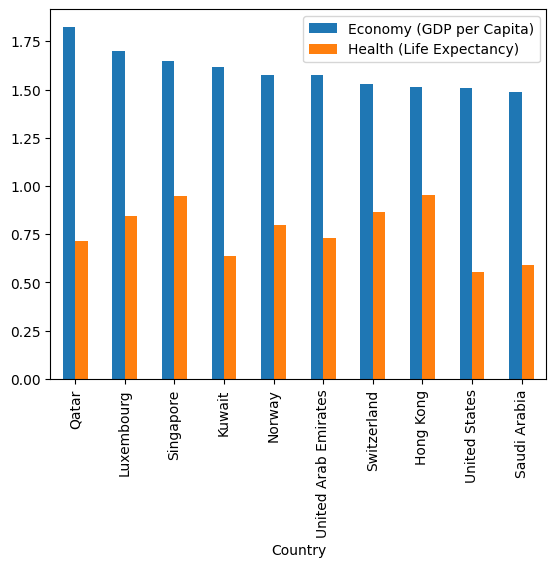

In [20]:
# GDP per capita and Healthy Life Expectancy of the top 10 countries
sorted_df = df[['Country', 'Economy (GDP per Capita)', 'Health (Life Expectancy)']].sort_values(
    by=['Economy (GDP per Capita)', 'Health (Life Expectancy)'],
    ascending=False
)
top_10=sorted_df.head(10)
top_10.plot(x='Country', y=['Economy (GDP per Capita)', 'Health (Life Expectancy)'], kind='bar')

The correlation between the Economy (GDP per Capita), Family, Health (Life Expectancy), Freedom, Trust (Government Corruption), Generosity, and Happiness Score. The correlation matrix is presented in the form of heatmap

Correlation Matrix:


,Happiness Score,Economy (GDP per Capita),Family,Health (Life Expectancy),Freedom,Trust (Government Corruption),Generosity
Happiness Score,1.000000,0.789625,0.739252,0.759471,0.566807,0.402032,0.156848
Economy (GDP per Capita),0.789625,1.000000,0.668984,0.825699,0.360998,0.286069,-0.022072
Family,0.739252,0.668984,1.000000,0.586163,0.450194,0.213561,0.089629
Health (Life Expectancy),0.759471,0.825699,0.586163,1.000000,0.348028,0.261928,0.069760
Freedom,0.566807,0.360998,0.450194,0.348028,1.000000,0.502030,0.361792
Trust (Government Corruption),0.402032,0.286069,0.213561,0.261928,0.502030,1.000000,0.305930
Generosity,0.156848,-0.022072,0.089629,0.069760,0.361792,0.305930,1.000000


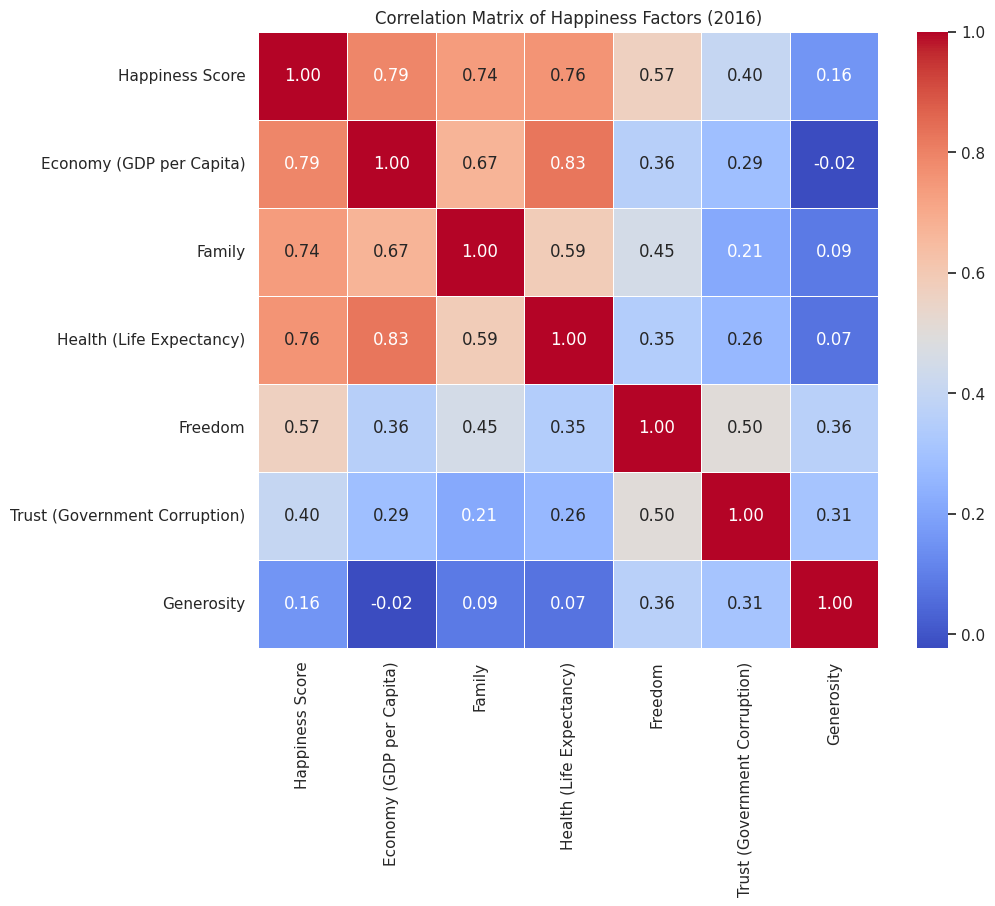

In [31]:
# Define the columns to check for correlation
columns_of_interest = [
    'Happiness Score',
    'Economy (GDP per Capita)',
    'Family',
    'Health (Life Expectancy)',
    'Freedom',
    'Trust (Government Corruption)',
    'Generosity'
]

# Calculate the correlation matrix
correlation_matrix = df[columns_of_interest].corr()

# Display the correlation numerical matrix
print("Correlation Matrix:")
display(correlation_matrix)

# Visualize with a heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix of Happiness Factors (2016)')
plt.show()

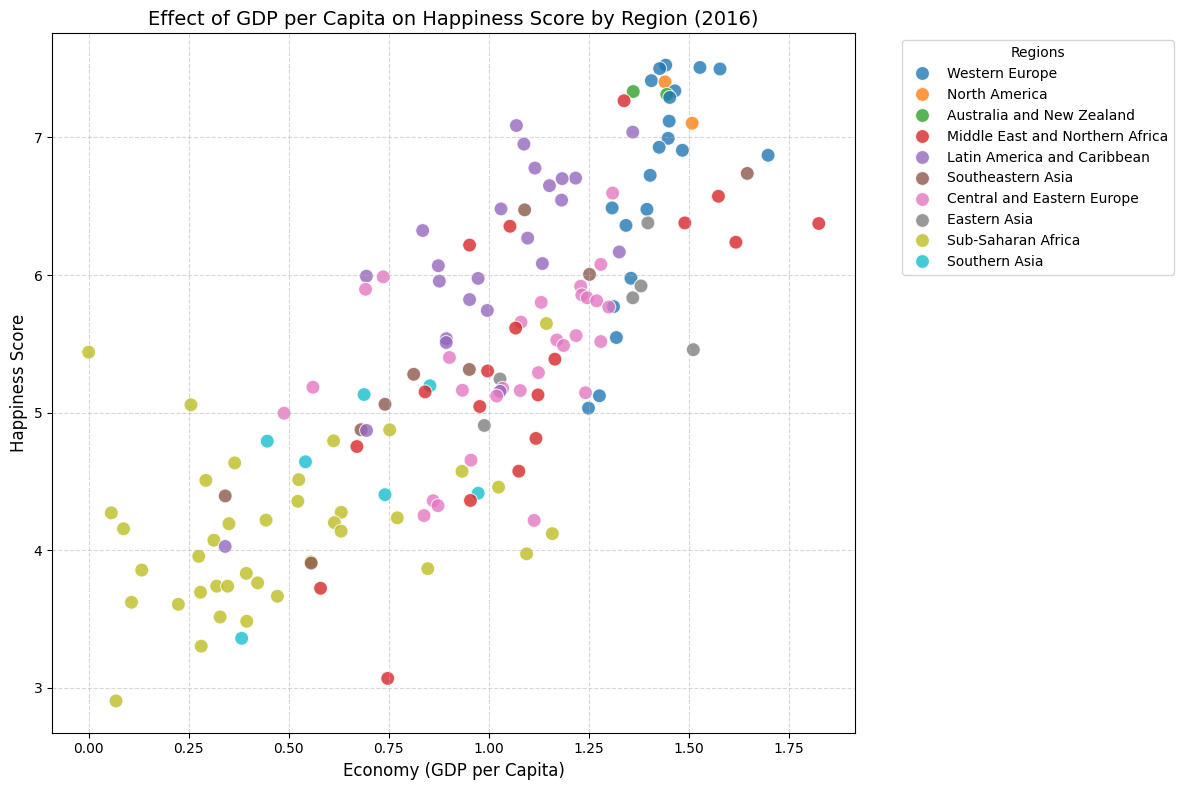

In [24]:
# a scatter plot to observe GDP per Capita vs Happiness Score across different Regions
plt.figure(figsize=(12, 8))
sns.scatterplot(
    data=df,
    x='Economy (GDP per Capita)',
    y='Happiness Score',
    hue='Region',
    palette='tab10',
    s=100,
    alpha=0.8
)

plt.title('Effect of GDP per Capita on Happiness Score by Region (2016)', fontsize=14)
plt.xlabel('Economy (GDP per Capita)', fontsize=12)
plt.ylabel('Happiness Score', fontsize=12)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title='Regions')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

The average Happiness Score for each Region presented in a pie chart

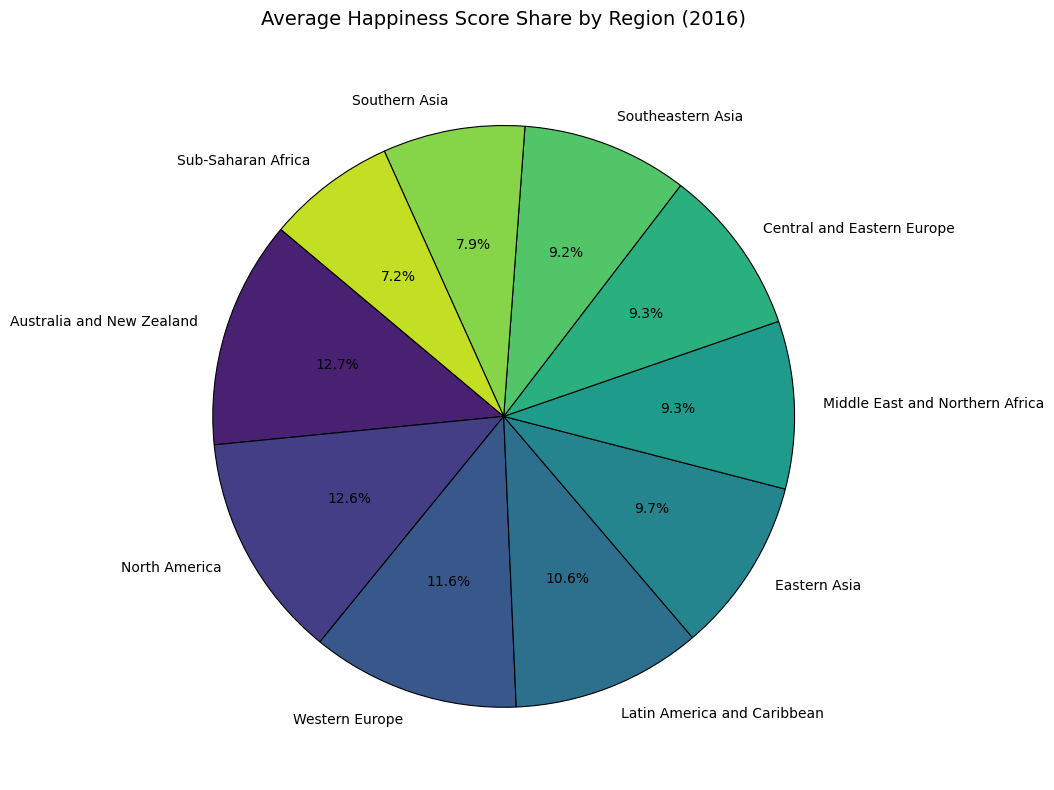

In [25]:
# Aggregate the average Happiness Score by Region
region_happiness = df.groupby('Region')['Happiness Score'].mean().sort_values(ascending=False)

# Create a pie chart
plt.figure(figsize=(10, 8))
plt.pie(
    region_happiness,
    labels=region_happiness.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=sns.color_palette('viridis', len(region_happiness)),
    wedgeprops={'edgecolor': 'black', 'linewidth': 0.8}
)

plt.title('Average Happiness Score Share by Region (2016)', fontsize=14, pad=20)
plt.tight_layout()
plt.show()

A map that shows GDP per capita of countries and includes Healthy Life Expectancy

In [29]:
import folium
import requests

# 1. Fetch World GeoJSON boundaries
geojson_url = 'https://raw.githubusercontent.com/johan/world.geo.json/master/countries.geo.json'
world_geojson = requests.get(geojson_url).json()

# 2. Create the base map
m = folium.Map(location=[20, 0], zoom_start=2)

# 3. Add Choropleth map coloring countries by GDP per Capita
folium.Choropleth(
    geo_data=world_geojson,
    name='GDP per Capita',
    data=df,
    columns=['Country', 'Economy (GDP per Capita)'],
    key_on='feature.properties.name',
    fill_color='YlGnBu',
    fill_opacity=0.7,
    line_opacity=0.2,
    legend_name='Economy (GDP per Capita)',
    nan_fill_color='white'
).add_to(m)

# 4. Add simple tooltips to show Country names on hover
folium.GeoJson(
    world_geojson,
    style_function=lambda x: {'fillColor': '#00000000', 'color': '#00000000'},
    tooltip=folium.GeoJsonTooltip(
        fields=['name'],
        aliases=['Country:'],
        localize=True
    )
).add_to(m)

# Display the map
m

# Global Happiness Insights Dashboard (2016)

This dashboard brings together our core exploratory data analyses of the **World Happiness Report (2016)** to explore what truly drives global happiness.

### Narrative Summary
1. **The Regional Picture:** Looking at our **Average Happiness Score Share**, regions like *Australia and New Zealand*, *North America*, and *Western Europe* stand out as leading in overall well-being, while *Sub-Saharan Africa* shows room for development.
2. **The Power of Prosperity:** Our **GDP per Capita vs. Happiness** scatter plot reveals a strong upward trajectory: countries with higher economic output consistently report higher happiness levels.
3. **Deciphering Key Drivers:** In our **Correlation Matrix**, we see that **Economy (GDP per Capita)** and **Health (Life Expectancy)** are the strongest positive correlates of happiness, followed closely by social safety nets (**Family**).
4. **Leading by Example:** Plotting the **Top 10 Economies** highlights the concurrent levels of economic strength and healthy life expectancy among the world's leading nations.

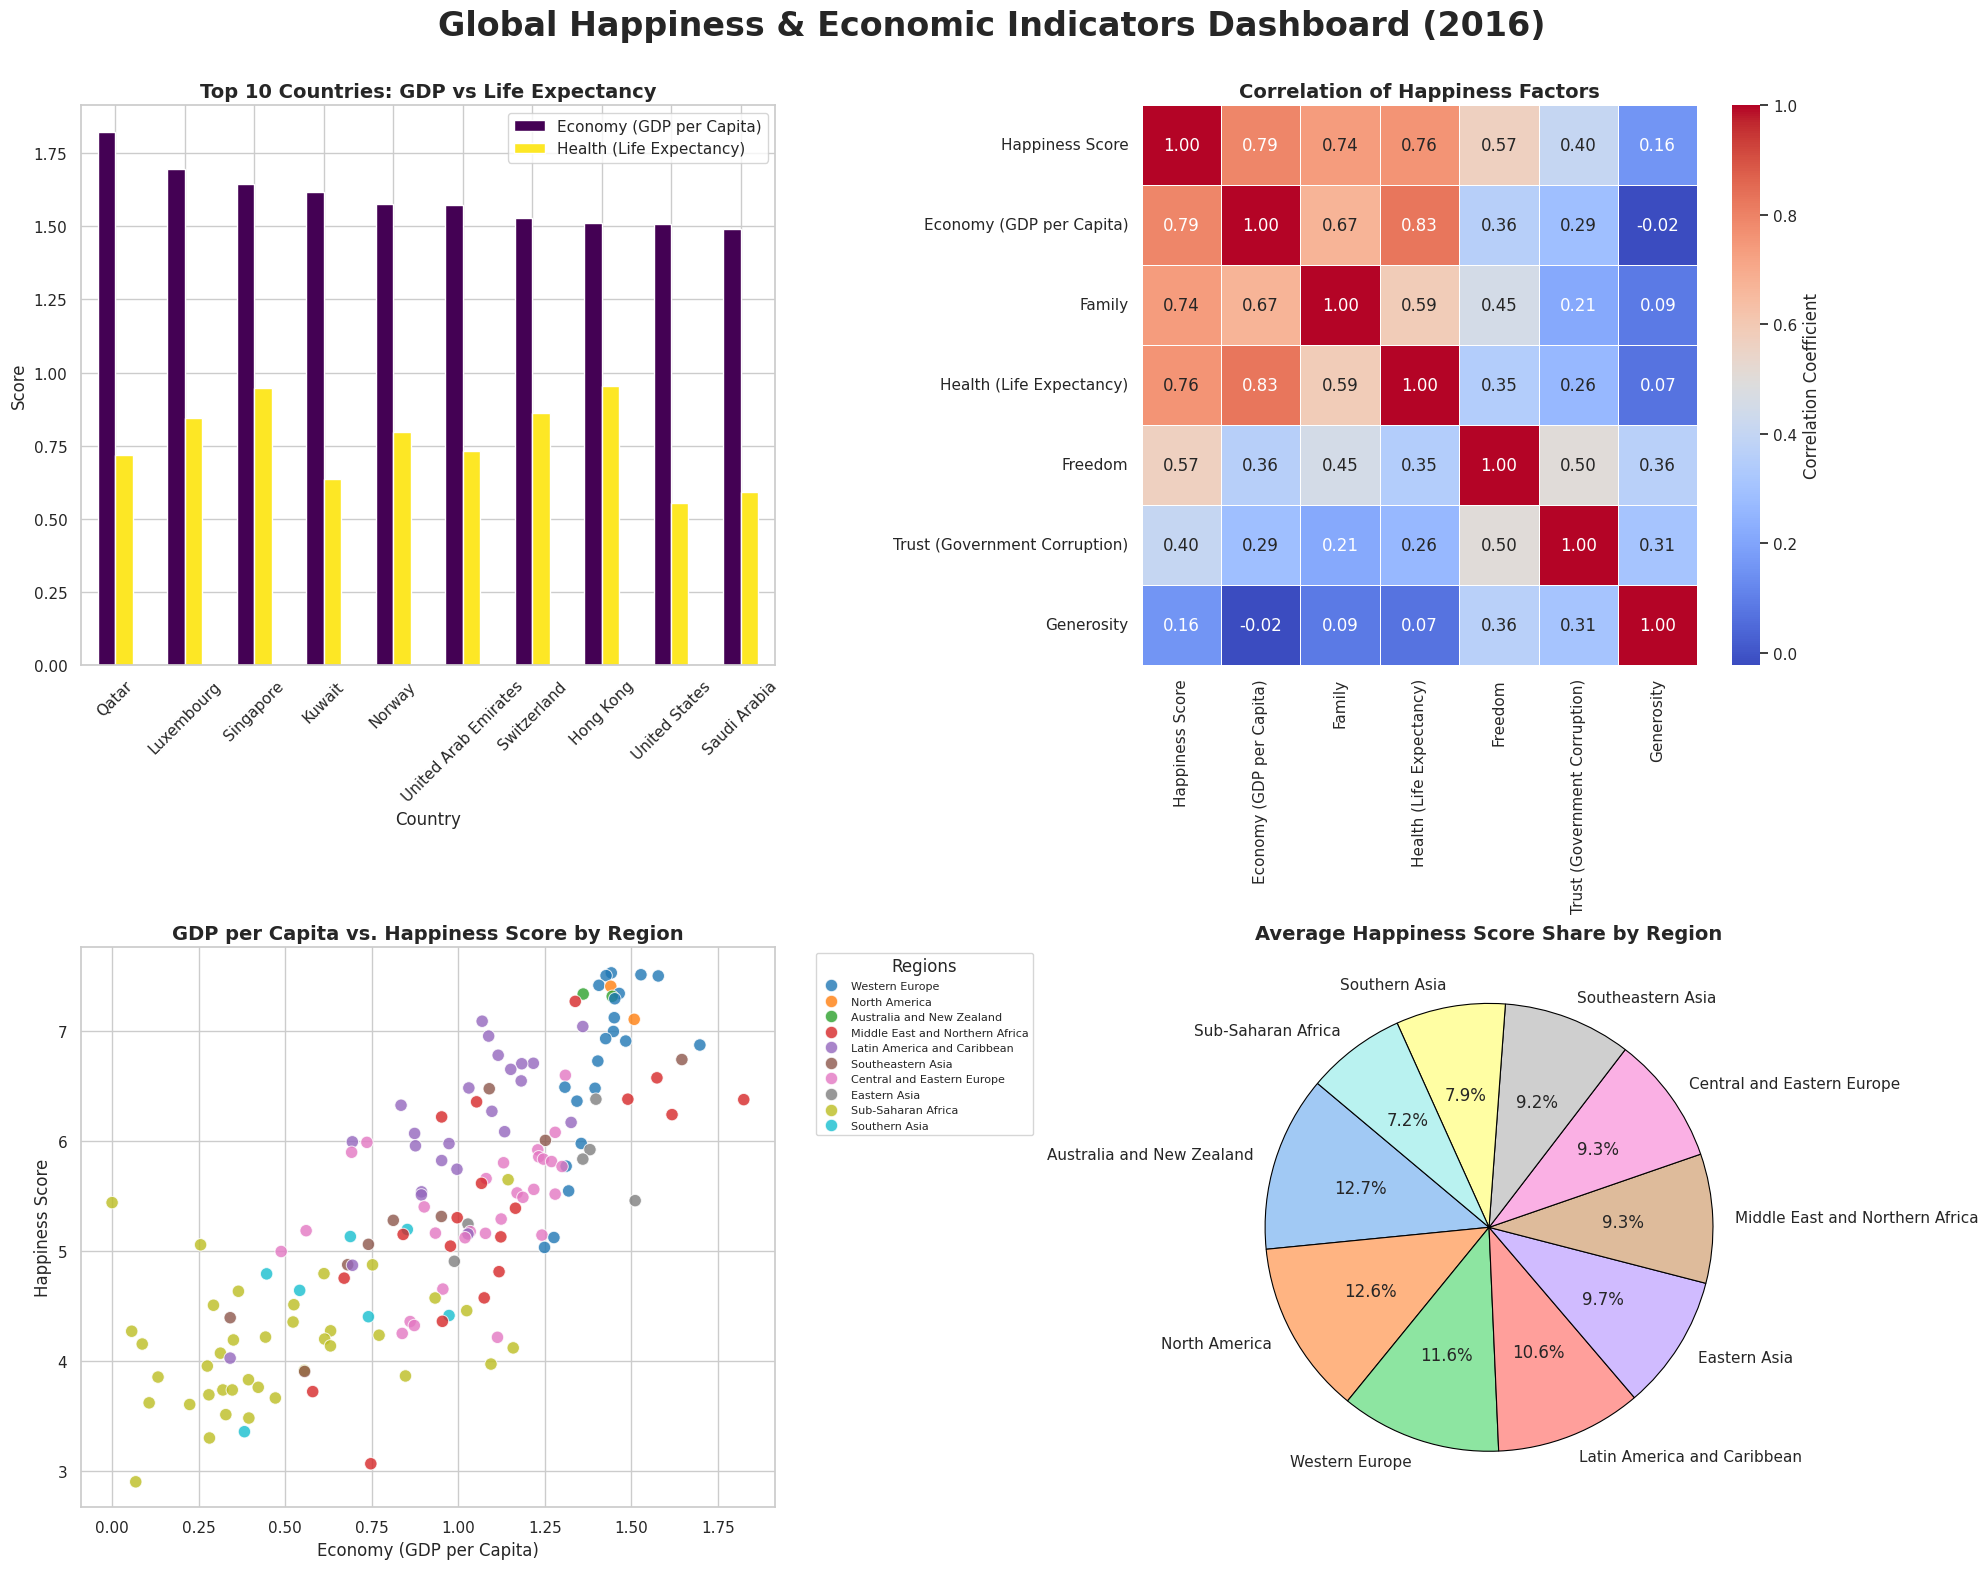

In [30]:
# Set the aesthetic style
sns.set_theme(style="whitegrid")

# Create a 2x2 grid subplot canvas
fig, axes = plt.subplots(2, 2, figsize=(20, 16))
fig.suptitle('Global Happiness & Economic Indicators Dashboard (2016)', fontsize=24, fontweight='bold', y=0.98)

# --- 1. Top Left: GDP & Life Expectancy for Top 10 Countries ---
top_10.plot(x='Country', y=['Economy (GDP per Capita)', 'Health (Life Expectancy)'], kind='bar', ax=axes[0, 0], colormap='viridis')
axes[0, 0].set_title('Top 10 Countries: GDP vs Life Expectancy', fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel('Country')
axes[0, 0].set_ylabel('Score')
axes[0, 0].tick_params(axis='x', rotation=45)

# --- 2. Top Right: Correlation Heatmap ---
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, ax=axes[0, 1], cbar_kws={'label': 'Correlation Coefficient'})
axes[0, 1].set_title('Correlation of Happiness Factors', fontsize=14, fontweight='bold')

# --- 3. Bottom Left: Scatter Plot ---
sns.scatterplot(
    data=df,
    x='Economy (GDP per Capita)',
    y='Happiness Score',
    hue='Region',
    palette='tab10',
    s=80,
    alpha=0.8,
    ax=axes[1, 0]
)
axes[1, 0].set_title('GDP per Capita vs. Happiness Score by Region', fontsize=14, fontweight='bold')
axes[1, 0].set_xlabel('Economy (GDP per Capita)')
axes[1, 0].set_ylabel('Happiness Score')
axes[1, 0].legend(title='Regions', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)

# --- 4. Bottom Right: Regional Happiness Share ---
axes[1, 1].pie(
    region_happiness,
    labels=region_happiness.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=sns.color_palette('pastel', len(region_happiness)),
    wedgeprops={'edgecolor': 'black', 'linewidth': 0.8}
)
axes[1, 1].set_title('Average Happiness Score Share by Region', fontsize=14, fontweight='bold')

# Adjust spacing dynamically to avoid overlaps
plt.tight_layout()
plt.subplots_adjust(top=0.92)
plt.show()